# Redes Convolucionales LeNet-5 para Neumonía
## TC2035 - Diseño de Redes Neuronales y Aprendizaje Profundo
### A00838589 - Steffany Mishell Lara Muy

El fin en mente de la presente tarea es poder crear una red neuronal convolucional, de manera que se modifiquen componentes en la red, estructura e hiperparámetros con el objetivo de experimentar, tomando como base el tutorial inicial.

Para este caso puntual, se hará uso del dataset OCTMNIST proveniente de MedMNIST, útils para clasificación biomédica de imágenes. Este dataset posee más de 100,000 tomografías de imágenes para enfermedades en la retina. El dataset está comprimido en 4 diagnósticos generales: neovascularización coroidea que se identifica con la etiqueta 0, edema macular diabético, identificado con la etiqueta 1 y drusas identificadas con la etiqueta 2, la etiqueta 3 identifica una retina normal.




In [2]:
!pip install medmnist

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 115.9/115.9 kB 9.7 MB/s eta 0:00:00


In [3]:
# IMPORTAR LIBRERÍAS
import tensorflow as tf #Para construir y entrenar la red
import tensorflow_datasets as tfds
import matplotlib #graficas
import matplotlib.pyplot as plt
import numpy as np#manejo de arreglos
from numpy import array
from sklearn.metrics import classification_report #para métricas de efectividad
import time
from sklearn.metrics import confusion_matrix
import sklearn.model_selection as model_selection
#dataset para diagnóstico biomédico de retina
from medmnist import OCTMNIST
import torchvision.transforms as transforms
from tensorflow.keras.utils import to_categorical

In [4]:
# Saber un poco de los datasets
print(tfds.list_builders())
import tensorflow_datasets as tfds

builders = tfds.list_builders()
N = 20

print(len(builders))

['abstract_reasoning', 'accentdb', 'aeslc', 'aflw2k3d', 'ag_news_subset', 'ai2_arc', 'ai2_arc_with_ir', 'ai2dcaption', 'aloha_mobile', 'amazon_us_reviews', 'anli', 'answer_equivalence', 'arc', 'asimov_dilemmas_auto_val', 'asimov_dilemmas_scifi_train', 'asimov_dilemmas_scifi_val', 'asimov_injury_val', 'asimov_multimodal_auto_val', 'asimov_multimodal_manual_val', 'asqa', 'asset', 'assin2', 'asu_table_top_converted_externally_to_rlds', 'austin_buds_dataset_converted_externally_to_rlds', 'austin_sailor_dataset_converted_externally_to_rlds', 'austin_sirius_dataset_converted_externally_to_rlds', 'bair_robot_pushing_small', 'bc_z', 'bccd', 'beans', 'bee_dataset', 'beir', 'berkeley_autolab_ur5', 'berkeley_cable_routing', 'berkeley_fanuc_manipulation', 'berkeley_gnm_cory_hall', 'berkeley_gnm_recon', 'berkeley_gnm_sac_son', 'berkeley_mvp_converted_externally_to_rlds', 'berkeley_rpt_converted_externally_to_rlds', 'big_patent', 'bigearthnet', 'billsum', 'binarized_mnist', 'binary_alpha_digits', 'b

In [5]:
# OBTENER DATOS DE ENTRENAMIENTO Y TEST

#primero descargo los splits
train_dataset = OCTMNIST(split='train',download=True,transform=transforms.ToTensor())
test_dataset = OCTMNIST(split='test',download=True,transform=transforms.ToTensor())

#extraigo imágenes y etiquetas
x_train, y_train = train_dataset.imgs, train_dataset.labels
x_test, y_test = test_dataset.imgs, test_dataset.labels

# Preprocesamiento
x_train = x_train.reshape(-1, 28, 28, 1).astype('float32') / 255.0 #para obtener el formato de cant entradada, alto, ancho y canal 1 blanco y negro
x_test = x_test.reshape(-1, 28, 28, 1).astype('float32') / 255.0

#one hot encoding de y es realizado despúes de mostrar ejemplos de imagen

print("x_train shape:", x_train.shape)
print(x_train.shape[0], "train samples")
print(x_test.shape[0], "test samples")

print("y_train shape:", y_train.shape)
print(y_train.shape[0], "train samples")
print(y_test.shape[0], "test samples")


100%|██████████| 54.9M/54.9M [00:00<00:00, 62.6MB/s]


x_train shape: (97477, 28, 28, 1)
97477 train samples
1000 test samples
y_train shape: (97477, 1)
97477 train samples
1000 test samples


In [6]:
# despliega las dimensiones de los arreglos
print(x_train.shape)
print(x_test.shape)
print(y_train.shape)
print(y_test.shape)

(97477, 28, 28, 1)
(1000, 28, 28, 1)
(97477, 1)
(1000, 1)


In [7]:
print(train_dataset.imgs)
print("Forma de y_train después de to_categorical:", y_train.shape)
print("Primeras 5 etiquetas (one-hot):", y_train[:5])

[[[ 23  24  25 ...  25  25  25]
  [ 23  24  25 ...  25  25  25]
  [ 22  24  25 ...  24  24  24]
  ...
  [ 13  13  13 ...  29  31  32]
  [ 12  12  12 ...  19  21  21]
  [ 10  10  10 ...  12  14  14]]

 [[ 34  33  31 ... 102 111 120]
  [ 32  31  30 ...  28  30  31]
  [ 28  27  26 ...  36  34  32]
  ...
  [ 11  11  12 ...  15  14  14]
  [ 27  24  21 ...  14  14  14]
  [197 190 180 ...  14  14  13]]

 [[172 168 161 ...  30  27  27]
  [ 31  31  31 ...  30  27  26]
  [ 29  30  31 ...  26  23  22]
  ...
  [ 17  17  16 ...  13  13  13]
  [ 16  15  14 ...  12  12  12]
  [ 15  14  13 ...  11  11  11]]

 ...

 [[ 35  41  52 ... 255 255 255]
  [ 42  39  35 ... 230 237 245]
  [ 28  27  26 ...  66  74  81]
  ...
  [ 15  15  15 ...  17  17  17]
  [ 14  14  14 ...  15  15  15]
  [ 13  13  13 ...  14  14  14]]

 [[ 28  27  28 ... 142 159 170]
  [ 28  28  28 ...  24  33  37]
  [ 27  27  27 ...  33  34  32]
  ...
  [ 11   9   8 ...  12  12  12]
  [104  96  83 ...  11  11  10]
  [255 255 245 ...  10  10  

In [8]:
dicc = {0: "Neovascularización Coroidea",
        1: "Edema macular diabético",
        2: "Drusas",
        3: "Retina Normal"}
print(y_train)


y_train = np.squeeze(y_train)

print(y_train)  # -> [0 1 2 0 3 0]
print(dicc[3])

[[0]
 [3]
 [3]
 ...
 [0]
 [3]
 [0]]
[0 3 3 ... 0 3 0]
Retina Normal


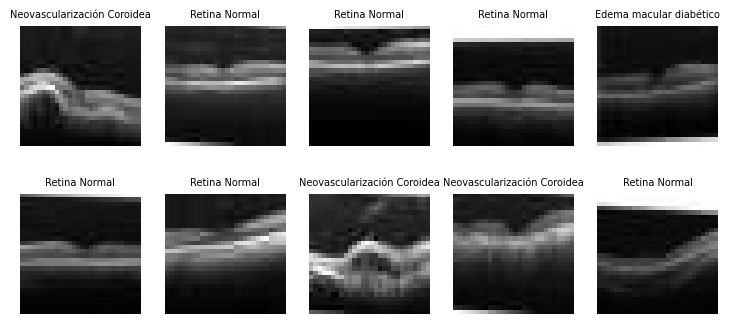

In [9]:
# despliega algunas imágenes del dataset
cc = [0,1,3,5,6,8,21,18,23,28]  # un ejemplo de cada clase/objeto.
fig=plt.figure(figsize=(9,4)) # figure size, inches
k=1
for i in cc:
  fig.add_subplot(2, 5, k)
  plt.imshow(x_train[i], cmap='gray')
  plt.title(dicc[y_train[i]],fontsize=7)
  plt.axis('off')
  k += 1

In [10]:
#one hot encoding
ytrain = tf.keras.utils.to_categorical(y_train, num_classes=4) #importante num classes?
ytest = tf.keras.utils.to_categorical(y_test, num_classes=4)
print(y_train)
print(y_train[0])
print(1234567890)
print(ytrain)
print(ytrain[0])



[0 3 3 ... 0 3 0]
0
1234567890
[[1. 0. 0. 0.]
 [0. 0. 0. 1.]
 [0. 0. 0. 1.]
 ...
 [1. 0. 0. 0.]
 [0. 0. 0. 1.]
 [1. 0. 0. 0.]]
[1. 0. 0. 0.]


In [11]:
print(ytrain.shape)

(97477, 4)


In [12]:
# crea el modelo LeNet-5 ACÁ SE MODIFICAN LOS COMPONENTES DE LA RED
model = tf.keras.models.Sequential([

   # C1: feature maps - Convolutional layer:
   tf.keras.layers.Conv2D(filters=32, kernel_size=(5,5), strides=(1,1), padding='same', activation='relu'),

   # S2: Subsampling - Pooling layer:
   tf.keras.layers.MaxPooling2D(pool_size=(2,2), strides=(2,2), padding='valid'),

   # C3: feature maps: Convolutional layer:
   tf.keras.layers.Conv2D(filters=64, kernel_size=(5,5), strides=(1,1), padding='valid', activation='relu'),

   # S4: Subsampling - Pooling layer:
   tf.keras.layers.MaxPooling2D(pool_size=(2,2), strides=(2,2), padding='valid'),

   # C5: Flatten & Fully connection:
   tf.keras.layers.Flatten(),
   tf.keras.layers.Dropout(0.5),  # Agregado: Reduce sobreajuste
   tf.keras.layers.Dense(120, activation='relu'),

   # F6: Fully conection:
   tf.keras.layers.Dense(84, activation='relu'),

   #Output: Softmax
   tf.keras.layers.Dense(4,activation=tf.nn.softmax)
   ])

In [13]:
print(y_test.shape)

(1000, 1)


In [14]:
# define algunos hiper-parámetros
n_epochs=15
n_batch=64
learning_rate=0.001

opt = tf.keras.optimizers.Adam(learning_rate=learning_rate)
lr_scheduler = tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3)

In [15]:
# configura el modelo para entrenamiento
model.compile(optimizer=opt,
   loss='categorical_crossentropy',
   metrics=['accuracy'])

In [16]:
print(x_train.shape)
print(ytrain.shape)

print(x_test.shape)
print(ytest.shape)

(97477, 28, 28, 1)
(97477, 4)
(1000, 28, 28, 1)
(1000, 4)


In [17]:
#Se para la ejecución para evitar un sobreajuste
early_stop = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
# Entrena el modelo para un número fijo de épocas
Historia = model.fit(x_train, ytrain, validation_data=(x_test, ytest),
                     epochs=n_epochs, batch_size=n_batch)

Epoch 1/15
1524/1524 ━━━━━━━━━━━━━━━━━━━━ 170s 103ms/step - accuracy: 0.6997 - loss: 0.7846 - val_accuracy: 0.6790 - val_loss: 0.8275
Epoch 2/15
1524/1524 ━━━━━━━━━━━━━━━━━━━━ 197s 101ms/step - accuracy: 0.8431 - loss: 0.4509 - val_accuracy: 0.6870 - val_loss: 0.7466
Epoch 3/15
1524/1524 ━━━━━━━━━━━━━━━━━━━━ 202s 101ms/step - accuracy: 0.8596 - loss: 0.4032 - val_accuracy: 0.6890 - val_loss: 0.8387
Epoch 4/15
1524/1524 ━━━━━━━━━━━━━━━━━━━━ 203s 101ms/step - accuracy: 0.8708 - loss: 0.3668 - val_accuracy: 0.7130 - val_loss: 0.7091
Epoch 5/15
1524/1524 ━━━━━━━━━━━━━━━━━━━━ 199s 100ms/step - accuracy: 0.8799 - loss: 0.3444 - val_accuracy: 0.6980 - val_loss: 0.7290
Epoch 6/15
1524/1524 ━━━━━━━━━━━━━━━━━━━━ 202s 100ms/step - accuracy: 0.8825 - loss: 0.3325 - val_accuracy: 0.6970 - val_loss: 0.7356
Epoch 7/15
1524/1524 ━━━━━━━━━━━━━━━━━━━━ 153s 101ms/step - accuracy: 0.8885 - loss: 0.3169 - val_accuracy: 0.6840 - val_loss: 0.8443
Epoch 8/15
1524/1524 ━━━━━━━━━━━━━━━━━━━━ 154s 101ms/step - ac

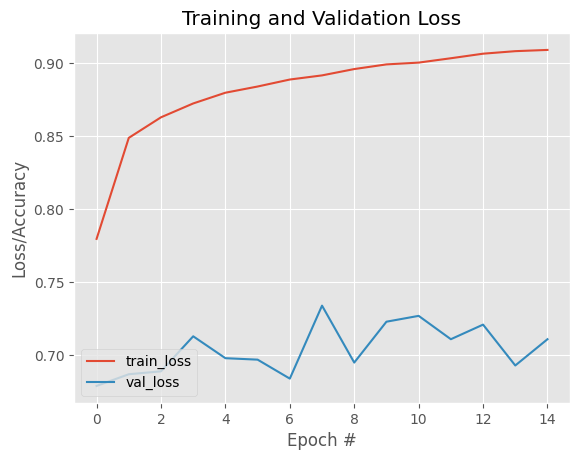

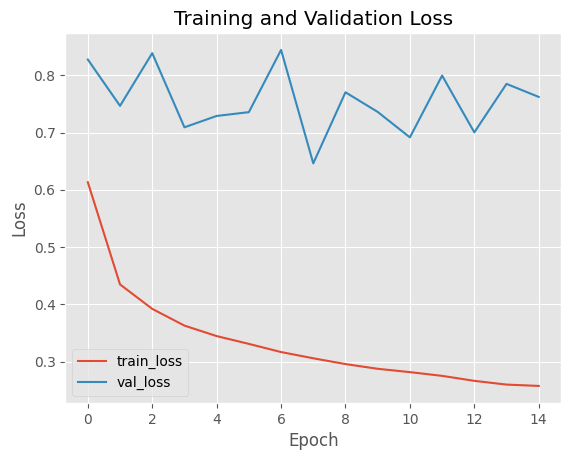

In [18]:
#CURVAS DE APRENDIZAJE
H = Historia
plt.style.use("ggplot")
plt.figure()
plt.plot(np.arange(0, n_epochs), H.history["accuracy"], label="train_loss")
plt.plot(np.arange(0, n_epochs), H.history["val_accuracy"],label="val_loss")
plt.title("Training and Validation Loss")
plt.xlabel("Epoch #")
plt.ylabel("Loss/Accuracy")
plt.legend(loc="lower left")
plt.show()


plt.figure()
plt.plot(np.arange(0,n_epochs),H.history["loss"],label="train_loss")
plt.plot(np.arange(0,n_epochs),H.history["val_loss"],label="val_loss")
plt.title("Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.show()

In [19]:
# estadísticas de desempeño de la red
labels = ["0","1","2","3"]
predictions = model.predict(x_test, batch_size=n_batch)
print(classification_report(ytest.argmax(axis=1),
      predictions.argmax(axis=1),target_names=labels))

16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 30ms/step
              precision    recall  f1-score   support

           0       0.58      0.98      0.73       250
           1       0.95      0.72      0.82       250
           2       0.92      0.20      0.32       250
           3       0.71      0.95      0.81       250

    accuracy                           0.71      1000
   macro avg       0.79      0.71      0.67      1000
weighted avg       0.79      0.71      0.67      1000



In [20]:
# MATRIZ DE CONFUSIÓN
confusion_matrix(ytest.argmax(axis=1),predictions.argmax(axis=1))


array([[244,   3,   0,   3],
       [ 52, 181,   2,  15],
       [116,   4,  49,  81],
       [  8,   3,   2, 237]])

In [21]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 10, 10, 64)     │        51,264 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 120)            │       192,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 84)             │        10,164 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 4)              │           340 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 764,162 (2.92 MB)

 Trainable params: 254,720 (995.00 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 509,442 (1.94 MB)

In [23]:
# PARÁMETROS DE LA RED
# Cálculo manual de parámetros (equivalente al de tu maestro)
print("Parámetros del Layer conv2d: " + str(1 * (5*5) * 32 + 32))  # 1 canal entrada, 32 filtros
print("Parámetros del Layer conv2d_1: " + str(32 * (5*5) * 64 + 64))  # 32 canales entrada, 64 filtros
print("Parámetros del Layer dense: " + str(1600 * 120 + 120))  # 5*5*64 = 1600 entradas, 120 neuronas
print("Parámetros del Layer dense_1: " + str(120 * 84 + 84))  # 120 entradas, 84 neuronas
print("Parámetros del Layer dense_2: " + str(84 * 4 + 4))  # 84 entradas, 4 neuronas

Parámetros del Layer conv2d: 832
Parámetros del Layer conv2d_1: 51264
Parámetros del Layer dense: 192120
Parámetros del Layer dense_1: 10164
Parámetros del Layer dense_2: 340


### Conclusión y Reflexión

Durante esta actividad tuve la oportunidad de comprender como utilizar la red neuronal LeNet 5, que fue de las pioneras CNN. Para eso tomé como base el código del maestro, que tiene como dataset MNIST que son números.

Puntualmente, cambié mi base de datos a OCTMNIST que proviene de datos médicos y tiene como finalidad diagnosticar distintas enfermedades relacionadas con la retina ocular por medio de tomografías. Se divide en 4 categorías: neovascularización coroidea que se identifica con la etiqueta 0, edema macular diabético, identificado con la etiqueta 1 y drusas identificadas con la etiqueta 2, la etiqueta 3 identifica una retina normal.

El primer cambio que hice a nivel estructural, y mas relevante, sería la importación de los datos. Fue más complicado porque no use direcamatne los datasets que keras trae por defecto si no que tuve q bajar la librería médica. Comprendí que tanto los datos de entrenamiento como dataset tienen una estructura puntual de array y no se puede aplicar solo así el entrenamiento de la CNN, tuve que remodelar los arrays de modo que quedara en su descripción de "shape" cantidad de datos, ancho, alto y el canal que son los colores, para mi caso puntual era 1 porque es blanco y negro.

Posteriormente, cambié los datos a categóricos, de manera que las clases cambian de enteras a un código binario usando one hot encoding.

Para el modelo, hice cambios relevantes. El primero fue aumentar la cantidad de filtros en la primera convolution layer de 6 a 32, la razón es porque tengo datos médicos y necesito que la primera capa capte de la mejor forma mis imágenes. El kernel size lo puse de 5x5 por la misma razón, strides lo puse de 1,1 para que vaya lento al inicio, el padding lo coloqué como same para evitar perder píxeles en los bordes y la función de activación la cambié a RELU porque mantiene los valores positivos mientras que tanh transforma los valores entre -1 y 1 de manera que mis valores de entrada al ser de textuaras, no se puede capturar bien y los gradientes se vuelven pequeños, así bajando mi accuracy.

Para los demás componentes también cambie a RELU a excepción del de salida donde puse softmax porque quería la probabilidad de ser cada una de las clases de enfermedades, para las convoluciones fui aumentando el tamaño del filtro para que pudiera capturar de mejor manera los datos.

Los hiperparámetros modifiqué a 15 epocas dado que en la tarea de ejemplo no era significativo el cambio en la función de perdida. Con respecto a el n_batch lo reduje a 64 y también disminuí el learning rate. cambié el optimizador de sdg a adam con la finalidad de aprovechar el momentum dado que es un dataset de imágenes médicas y ocupa esa precisión y mejora en aprendizaje.

Pese a eso el modelo no tuvo tan buenos resutaldos, en general, para el accurazy tuvo un 0.71 siendo poco confiable cuando se habla de terminos médicos. Aunque según el entremaiento llegó al 0,9 pero los datos de prueba dicen lo contrario. Por otra parte, vemos que falla mucho en todas las métricas de la clase 2, en la confussion matrix se evidencia que la confunde con la clase 0 y 3 mayormente.

En conclusión, diría que LeNet5 aunque es una buena opción para redes neuronales debería limitarse a datasets sencillos como lo son números o reconocimientos más fáciles. Para términos médicos, buscaría CNN más nuevas como ResNet18. Pese a eso los resultados fueron decentes. Diría que lo más complicado de esta tarea fue comprender los componentes de una CNN y los posibles hiperparámetros. Esta versión que entregué es una mejorada dado que mi primera tarea utilizaba la función softmax como activación siempre y tuve un resultado de 0.5 en accurazy por lo que si hubo mejora. También añadí un early stop para evitar el sobre ajuste en esta versión.



###